# EPS surprises and weekly Nvidia/Nasdaq comovement

Short replication notebook accompanying [*The Case for an AI Bubble*](LINK_TO_LINKEDIN_POST):

- **Slide 15:** Nvidia's reported EPS surprises versus two-trading-day returns, an 11-observation linear fit, and the fitted zero-return EPS surprise.
- **Slide 26:** Historical weekly Nasdaq Composite/Nvidia return ratios, summarized by quantiles conditional on the size of Nvidia's weekly move.

EPS surprises are the source notebook's vendor-reported values (not recomputed from rounded EPS). EPS-event returns use Yahoo **adjusted closes**; weekly returns use **ordinary closes**. Data end on **October 23, 2026**. Requires `numpy`, `pandas`, `matplotlib`, `yfinance` and an internet connection to refresh prices.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# One price request for both analyses; adjusted NVDA closes for EPS and
# ordinary NVDA / ^IXIC closes for the weekly return ratios.
raw = yf.download(["NVDA", "^IXIC"], start="2024-02-20", end="2026-10-25",
                  auto_adjust=False, threads=False, progress=False)
adj_nvda = raw["Adj Close"]["NVDA"].dropna()
closes = raw["Close"][["NVDA", "^IXIC"]].dropna()
for prices in (adj_nvda, closes):
    prices.index = pd.to_datetime(prices.index).tz_localize(None).normalize()


      date  estimate  actual  surprise
2025-11-19      1.26    1.30      3.46
2026-02-25      1.54    1.62      5.32
2026-05-20      1.77    1.87      5.54
2026-08-26      2.09    2.22      6.16
OLS (n=11): two-day return (%) = 2.69 × surprise (%) -17.99
Zero fitted return: 6.68% EPS surprise


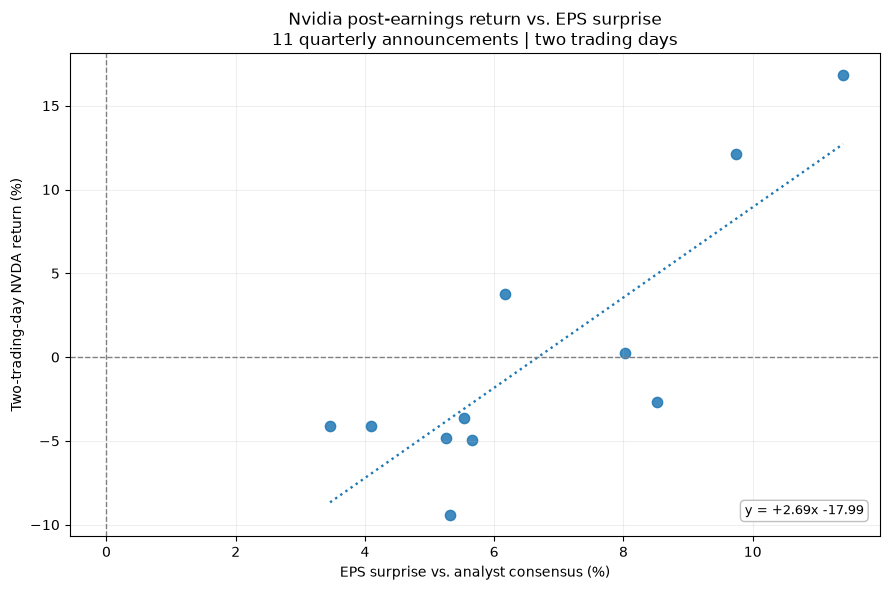

In [2]:
# Source notebook's normalized EPS observations; surprises are vendor-reported.
eps = pd.DataFrame([
    ("2024-02-21", .46, .52, 11.40), ("2024-05-22", .56, .61, 9.74),
    ("2024-08-28", .64, .68, 5.66), ("2024-11-20", .75, .81, 8.52),
    ("2025-02-26", .85, .89, 5.25), ("2025-05-28", .75, .81, 8.02),
    ("2025-08-27", 1.01, 1.05, 4.10), ("2025-11-19", 1.26, 1.30, 3.46),
    ("2026-02-25", 1.54, 1.62, 5.32), ("2026-05-20", 1.77, 1.87, 5.54),
    ("2026-08-26", 2.09, 2.22, 6.16),
], columns=["date", "estimate", "actual", "surprise"])
eps["date"] = pd.to_datetime(eps["date"])
eps["return_2d"] = [100 * (adj_nvda.iloc[adj_nvda.index.get_loc(d) + 2] / adj_nvda.loc[d] - 1)
                    for d in eps["date"]]
m, b = np.polyfit(eps["surprise"], eps["return_2d"], 1)
print(eps.tail(4)[["date", "estimate", "actual", "surprise"]].to_string(index=False))
print(f"OLS (n={len(eps)}): two-day return (%) = {m:.2f} × surprise (%) {b:+.2f}")
print(f"Zero fitted return: {-b/m:.2f}% EPS surprise")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(eps["surprise"], eps["return_2d"], s=55, alpha=.85)
xx = np.linspace(eps["surprise"].min(), eps["surprise"].max(), 100)
ax.plot(xx, m * xx + b, ":", lw=1.7)
ax.axhline(0, color="gray", lw=1, ls="--")
ax.axvline(0, color="gray", lw=1, ls="--")
ax.text(.98, .04, f"y = {m:+.2f}x {b:+.2f}", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=9, bbox={"boxstyle":"round,pad=.35", "fc":"white", "ec":".75"})
ax.set(xlabel="EPS surprise vs. analyst consensus (%)",
       ylabel="Two-trading-day NVDA return (%)",
       title=f"Nvidia post-earnings return vs. EPS surprise\n{len(eps)} quarterly announcements | two trading days")
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()


In [3]:
# Friday-ending weekly closes and corresponding return ratios.
weekly = closes.resample("W-FRI").last().loc["2024-10-18":"2026-10-23"].dropna()
r = weekly.pct_change().dropna()
r["ratio"] = (r["^IXIC"] / r["NVDA"]).replace([np.inf, -np.inf], np.nan)
rows = []
for threshold in (.03, .05, .08, .10):
    sample = r.loc[r["NVDA"].abs() > threshold, "ratio"].dropna()
    rows.append((f">{threshold:.0%}", len(sample), *sample.quantile([.25, .5, .75])))
summary = pd.DataFrame(rows, columns=["NVDA move", "N", "P25", "P50", "P75"]).set_index("NVDA move")
print(f"Weekly returns: {len(r)} observations, {r.index.min():%Y-%m-%d} to {r.index.max():%Y-%m-%d}")
print(summary.to_string(formatters={c: lambda v: f"{v:.5f}x" for c in ("P25", "P50", "P75")}))

Weekly returns: 105 observations, 2024-10-25 to 2026-10-23
            N      P25      P50      P75
NVDA move                               
>3%        59 0.14260x 0.39571x 0.53411x
>5%        35 0.22114x 0.39571x 0.53411x
>8%        15 0.28249x 0.43958x 0.53411x
>10%        5 0.41379x 0.44492x 0.44885x
